# Inside the Model: K-Nearest Neighbours

## Same observations, different neighbours

**30–35 minutes**

KNN makes a prediction by finding similar observations. In this exercise, you will make that decision yourself and investigate what happens when one feature is recorded in different units.

You should be familiar with Euclidean distance, the number of neighbours $k$ and majority voting. The short recap below is enough to begin.

### Learning objectives

By the end of this exercise, you should be able to:

- identify the observations that actually determine a KNN prediction;
- explain how changing one feature's units can change those observations;
- distinguish a change in the data's information from a change in the distance rule.

Keep your first prediction visible when you revise it. Work through Sections 1–3 before running Python. The optional extension is additional.


### The experiment

Predict the class of the query **$q=(0,0)$** using **$k=3$**, Euclidean distance and one equal vote per neighbour.

| ID | First feature $x_1$ | Second feature $x_2$ | Class |
|:--|--:|--:|--:|
| A1 | 1 | 6 | 0 |
| A2 | 2 | 5 | 0 |
| A3 | 3 | 4 | 0 |
| B1 | 4 | 1 | 1 |
| B2 | 5 | 1 | 1 |

These are two numerical measurements. Every row has equal importance in voting. We keep all five observations and use no fitted scaler. The two representations in the main exercise have distinct distances. The optional extension introduces a tie and states how to resolve it.

### Recall: distance, selection, vote

For this query, $d^2=x_1^2+x_2^2$. Ranking **squared** distances gives the same order as ranking distances: square root is increasing for nonnegative values.

As a separate worked example, the point $(2,1)$ has squared distance $2^2+1^2=5$ from the origin. Compute this quantity for each training point, select the three smallest, then count their labels. The nearest point alone does not decide a three-neighbour vote.

---


## 1. Predict before calculating

**About 4 minutes · No Python**

Sketch the five observations and the query. Which three points do you expect to be closest? Which class would their vote produce?

Give a reason for your selection. If two candidates look difficult to order, identify that uncertainty explicitly.

**Your prediction and sketch:**

_Write here before continuing._


## 2. Open the neighbour decision

**About 7 minutes · No Python**

Complete the squared-distance column, select exactly three points and apply the vote. You do not need to take square roots.

| ID | Squared distance $x_1^2+x_2^2$ | Selected among the three nearest? |
|:--|--:|:--|
| A1 | … | … |
| A2 | … | … |
| A3 | … | … |
| B1 | … | … |
| B2 | … | … |

Record the three selected labels and the resulting class. Explain any difference from your first prediction by referring to one distance comparison.

**Your calculation and explanation:**

_Write here._


## 3. Change one feature's units

**About 9 minutes · No Python**

Now record the **first feature in units half as large**. Its numerical values double: $x'_1=2x_1$. Apply this same change to both training observations and the query. The second feature, class labels, $k$ and voting rule stay fixed.

The query remains $(0,0)$. We still use ordinary Euclidean distance in the displayed coordinates; we do not undo the unit change with a scaler.

**Pause and predict:** Which observations will become less competitive as neighbours? Will the predicted class change? Explain before calculating.

**Your second prediction:** _Write here._

### Check the new distances

Use $d'^2=(2x_1)^2+x_2^2$. Complete a second distance column next to your first table, then select and vote again.

Identify at least one point that enters and one that leaves the neighbourhood. Explain why doubling the first feature changes its contribution to **squared** distance by a factor of four.

<details><summary>Hint: separate the two contributions</summary>

For each row, compare $x_1^2$ with $x_2^2$. Only the first contribution changes. Do not multiply the entire original distance by two.

</details>

**Your updated calculation and explanation:**

_Write here before Python._


---

## 4. Verify with short Python calculations

**About 7 minutes · Start only after Sections 1–3**

Complete the **two expressions** for squared distance. The supplied code sorts the distances, prints the selected labels and checks both predictions with the KNN classifier used in the lecture.

`np.argsort(d2)[:3]` means “the row positions of the three smallest values”. The plot outlines those selected points. You do not need to modify the plotting code.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

df = pd.DataFrame({'ID': ['A1', 'A2', 'A3', 'B1', 'B2'],
                   'first': [1, 2, 3, 4, 5],
                   'second': [6, 5, 4, 1, 1],
                   'class': [0, 0, 0, 1, 1]})
X = df[['first', 'second']].copy()
y = df['class']
query = pd.DataFrame({'first': [0], 'second': [0]})
X_new = X.copy()
X_new['first'] = 2 * X_new['first']


In [2]:
d2 = df['first']**2 + df['second']**2
d2_new = (2 * df['first'])**2 + df['second']**2


Both panels use equal horizontal and vertical units. The first coordinate has a wider range in the second panel because its recorded numbers doubled. Blue points are class 0 and red points are class 1. The black star is the query; black rings identify the selected neighbours.


ID  class  Original d2  Changed d2
A1      0           37          40
A2      0           29          41
A3      0           25          52
B1      1           17          65
B2      1           26         101


Original units : ['B1', 'A3', 'B2'] labels [1, 0, 1] -> class 1
First feature doubled : ['A1', 'A2', 'A3'] labels [0, 0, 0] -> class 0


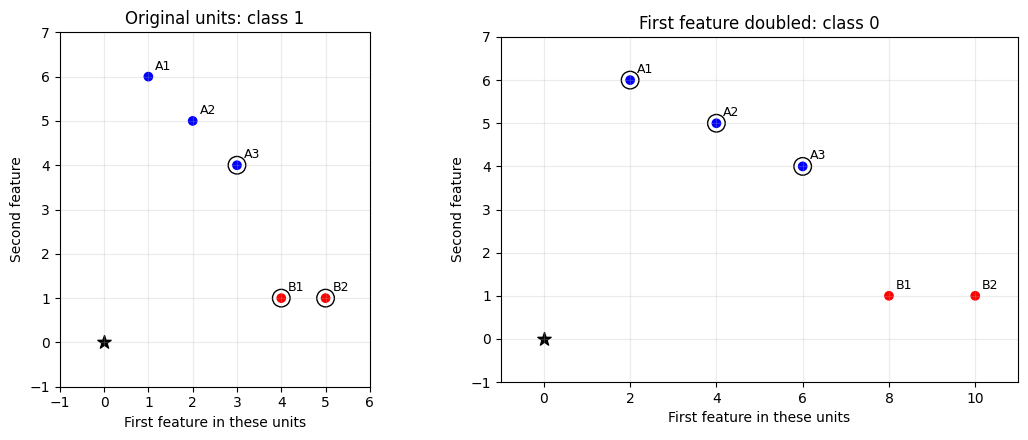

In [3]:
if d2 is None or d2_new is None:
    print('Complete the two distance expressions, then rerun this cell.')
else:
    table = df[['ID', 'class']].copy()
    table['Original d2'] = d2
    table['Changed d2'] = d2_new
    print(table.to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for panel in range(2):
        if panel == 0:
            points = X
            distances = d2
            title = 'Original units'
        else:
            points = X_new
            distances = d2_new
            title = 'First feature doubled'
        selected = np.argsort(distances)[:3]
        model = KNeighborsClassifier(n_neighbors=3, weights='uniform', metric='euclidean')
        model.fit(points, y)
        prediction = model.predict(query)[0]
        print(title, ':', df['ID'].iloc[selected].tolist(),
              'labels', y.iloc[selected].tolist(), '-> class', prediction)
        ax = axes[panel]
        ax.scatter(points['first'], points['second'], c=y, cmap='bwr', vmin=0, vmax=1)
        ax.scatter(points['first'].iloc[selected], points['second'].iloc[selected],
                   s=160, facecolors='none', edgecolors='black')
        ax.scatter(0, 0, marker='*', s=100, color='black', label='Query')
        for row in range(len(df)):
            ax.annotate(df['ID'].iloc[row], points.iloc[row],
                        xytext=(5, 5), textcoords='offset points', fontsize=9)
        ax.set_title(title + ': class ' + str(prediction))
        ax.set_xlabel('First feature in these units')
        ax.set_ylabel('Second feature')
        ax.set_xlim(-1, points['first'].max() + 1)
        ax.set_ylim(-1, 7)
        ax.set_aspect('equal', adjustable='box')
        ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


---

## 5. Explain the mechanism

**About 4 minutes**

1. Why can the prediction change even though we have not collected any new information or changed any labels?
2. Which part of the KNN procedure changed: distance ranking, the vote rule, or both? Use your two selected neighbour sets as evidence.
3. Before applying KNN to features with different units, what should you decide about the meaning of “similar”? Explain why a convenient scale is not, by itself, proof that it is scientifically appropriate.

**Your interpretation:** _Write two or three sentences per question._

## Optional extension: find the first change

**Allow a further 5–10 minutes**

Return to the **original table**. Now multiply only the first feature by a factor $s$, starting at $s=1$ and increasing towards $s=2$. Apply the factor to the original coordinates once, for both training observations and query:

$$d_s^2=s^2x_1^2+x_2^2.$$

Find the **first value of $s$ at which the predicted class can change**. You may use $t=s^2$ to make the distance formulas linear. Follow the competition for third place; not every change in distance order changes the selected set.

At your proposed boundary, check all five distances. State the prediction just below and just above it. For an exact tie, select the point that appears **earlier in the original table**. What is the prediction exactly at the boundary, and why does odd $k$ alone not settle it?

<details><summary>Hint</summary>

Compare the original third neighbour with the nearest excluded point. Check that no other excluded point enters earlier.

</details>

**Your calculation and explanation:** _Use exact arithmetic for the tie; a rounded computer result is not a tie proof._

---

## Takeaway

Complete: **“For KNN, choosing how to measure distance matters because …”** Support your sentence with one point that changed neighbour status.


---

# Solutions


## 1–2. Original representation

The squared distances for A1, A2, A3, B1 and B2 are **37, 29, 25, 17 and 26**. The nearest three are **B1, A3 and B2**, with labels **1, 0 and 1**. The prediction is **class 1**.

Accept a reasoned initial prediction even if it is wrong. A3 and B2 differ by only one unit of squared distance; the table resolves what can be hard to judge in a sketch. The increasing square-root transformation preserves all these strict comparisons.


## 3. Changed units

The new squared distances are **40, 41, 52, 65 and 101**. The nearest three are now **A1, A2 and A3**, all class 0. The prediction changes to **class 0**.

A1 and A2 enter; B1 and B2 leave. A3 remains. B1 and B2 have larger first-coordinate values, so their contributions from that coordinate increase most. The new rule is $4x_1^2+x_2^2$ for this query. It puts four times as much weight on squared first-coordinate differences while the second-coordinate weight stays fixed.


## 4–5. Interpretation and optional extension

The unit change is an invertible representation of the same measurements. Ordinary Euclidean distance in that new representation defines a different notion of proximity. The **ranking** changes; the uniform majority-vote rule does not. Applying the same transformation to the query is essential even though its zero coordinates make that transformation numerically invisible here.

A suitable distance should reflect which feature differences are meaningful for the application. Standardisation can prevent arbitrary units from dominating, but equal statistical scales do not establish equal scientific relevance or guarantee better predictions. This controlled example demonstrates sensitivity, not which representation will generalise better.

For the optional extension, put $t=s^2$. The squared distances in table order are

$$t+36,\quad4t+25,\quad9t+16,\quad16t+1,\quad25t+1.$$

At $t=1$, B2 is the third neighbour and A2 is the nearest excluded point. Their equality gives $4t+25=25t+1$, so $t=8/7$ and $s=\sqrt{8/7}\approx1.069045$.

Until that value, B1 and A3 remain closer than B2. A1 would catch B2 only at $t=35/24>8/7$, so it cannot enter earlier. At the boundary the ordered squared distances are $135/7$ (B1), $184/7$ (A3), $207/7$ (A2 and B2), and $260/7$ (A1).

Just below the boundary the selected labels are $(1,0,1)$, predicting 1. Just above it, A2 replaces B2 and the vote predicts 0. At equality, the stated table-order rule selects A2, so the prediction is 0. Choosing B2 instead would give 1. Odd $k$ prevents a tied binary vote once neighbours have been selected; it does not resolve a distance tie at the selection cutoff.

The factor $s$ is always measured from the original table. Applying it again to the already doubled coordinates would be a different experiment. Do not infer exact tie handling from a floating-point evaluation at the irrational boundary.
